# GDBN Data: Sanity Check

Before fitting anything, check that the dataset looks right. Each section ends with a **check** line that prints `OK` or `FLAG`.

1. Shape, dates, and missing values
2. Returns: sizes, extreme days, volatility
3. News sentiment: range and distribution
4. News attention: is there a trend over time?
5. Crisis check: March 2020
6. Correlations: do sectors move together?
7. News vs returns: same-day and next-day links
8. Summary of flags

**Kernel:** Python (thesis). Decisions about the model (e.g., whether to adjust attention) should be based on the **training period (2015–2021)** only.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

pd.set_option("display.precision", 4)
DATA = Path("data")

wide = pd.read_csv(DATA / "gdbn_wide.csv", index_col="date", parse_dates=True).sort_index()
split = pd.read_csv(DATA / "splits" / "split_labels.csv", index_col="date", parse_dates=True)["split"]
universe = pd.read_csv(DATA / "universe.csv").drop_duplicates("ticker")

RET = [c for c in wide.columns if c.endswith("_ret")]
SENT = [c for c in wide.columns if c.endswith("_sent")]
ATTN = [c for c in wide.columns if c.endswith("_attn")]
STOCKS = [c[:-5] for c in SENT]
SECTOR = dict(zip(universe["ticker"], universe["sector"]))
train = wide[split == "train"]

flags = {}
def check(name, ok, detail=""):
    flags[name] = ok
    print(f"[{'OK' if ok else 'FLAG'}] {name}" + (f": {detail}" if detail else ""))

## 1. Shape, dates, and missing values

In [2]:
print(f"{len(wide):,} trading days from {wide.index.min().date()} to {wide.index.max().date()}")
print(f"{len(RET)} returns + {len(SENT)} sentiment + {len(ATTN)} attention = {wide.shape[1]} variables")
print(split.value_counts().reindex(["train", "validation", "test"]))

check("95 variables", wide.shape[1] == 95, f"found {wide.shape[1]}")
check("No missing values", int(wide.isna().sum().sum()) == 0, f"{int(wide.isna().sum().sum())} missing cells")
check("No duplicate dates", not wide.index.duplicated().any())
gaps = wide.index.to_series().diff().dt.days
check("No gaps longer than 4 calendar days", gaps.max() <= 4, f"longest gap {int(gaps.max())} days")

2,516 trading days from 2015-01-02 to 2024-12-31
35 returns + 30 sentiment + 30 attention = 95 variables
split
train         1763
validation     251
test           502
Name: count, dtype: int64
[OK] 95 variables: found 95
[OK] No missing values: 0 missing cells
[OK] No duplicate dates
[OK] No gaps longer than 4 calendar days: longest gap 4 days


## 2. Returns

Daily returns are usually small (around ±1–2%), with occasional large moves. A single-day move above ±30% for a large company would be suspicious (possible data error).

In [3]:
ret_stats = pd.DataFrame({
    "mean (%)": wide[RET].mean() * 100,
    "std (%)": wide[RET].std() * 100,
    "annual vol (%)": wide[RET].std() * np.sqrt(252) * 100,
    "min (%)": wide[RET].min() * 100,
    "max (%)": wide[RET].max() * 100,
}).rename(index=lambda c: c[:-4]).sort_values("annual vol (%)")
ret_stats

,mean (%),std (%),annual vol (%),min (%),max (%)
GLD,0.0340,0.8894,14.1186,-5.3695,4.9122
TLT,0.0001,0.9647,15.3147,-6.6683,7.5196
SPY,0.0548,1.1096,17.6139,-10.9424,9.0603
KO,0.0344,1.1200,17.7797,-9.6725,6.4796
JNJ,0.0303,1.1369,18.0478,-10.0379,7.9977
PG,0.0422,1.1634,18.4677,-8.7373,12.0090
PEP,0.0373,1.1732,18.6243,-11.4283,12.9366
WMT,0.0625,1.3306,21.1233,-11.3758,11.7085
COST,0.0918,1.3588,21.5707,-12.4513,9.9595
MRK,0.0456,1.3607,21.5999,-9.8630,10.4080


In [4]:
# Largest single-day moves (look up whether each matches a real event)
moves = wide[RET].stack().rename("ret").reset_index()
moves.columns = ["date", "series", "ret"]
moves["abs"] = moves["ret"].abs()
print(moves.nlargest(10, "abs")[["date", "series", "ret"]].assign(ret=lambda d: (d["ret"] * 100).round(1)).to_string(index=False))

check("No single-day move above ±60%", moves["abs"].max() < 0.60, f"largest {moves['abs'].max():.1%}")
check("Average daily returns are small (|mean| < 0.5%)", (wide[RET].mean().abs() < 0.005).all())

      date   series   ret
2020-03-09  OXY_ret -50.5
2020-06-05  OXY_ret  33.7
2020-03-09  EOG_ret -32.0
2016-11-11 NVDA_ret  29.8
2020-03-09  SLB_ret -27.4
2022-02-03 META_ret -26.4
2020-03-09  USO_ret -25.3
2020-03-24  COP_ret  25.2
2020-04-21  USO_ret -25.1
2020-03-09  COP_ret -24.8
[OK] No single-day move above ±60%: largest 50.5%
[OK] Average daily returns are small (|mean| < 0.5%)


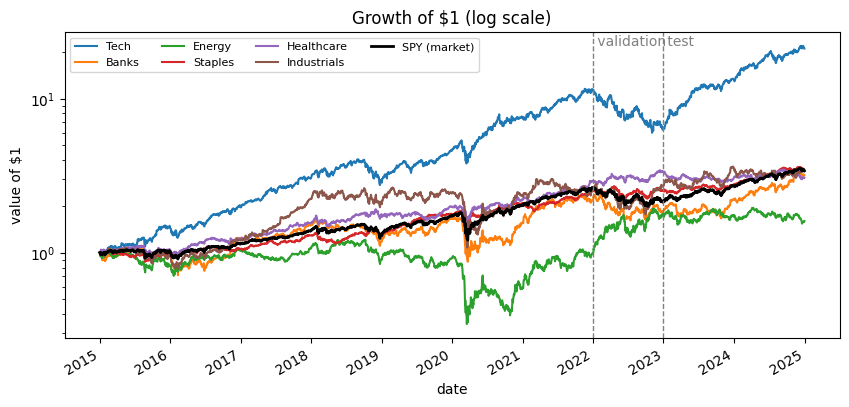

In [5]:
# Growth of $1 by sector (equal-weighted within sector)
fig, ax = plt.subplots(figsize=(10, 4.5))
for sector in ["Tech", "Banks", "Energy", "Staples", "Healthcare", "Industrials"]:
    cols = [f"{t}_ret" for t in STOCKS if SECTOR.get(t) == sector]
    (1 + wide[cols].mean(axis=1)).cumprod().plot(ax=ax, label=sector)
(1 + wide["SPY_ret"]).cumprod().plot(ax=ax, label="SPY (market)", color="black", lw=2)
for d, name in [("2022-01-01", "validation"), ("2023-01-01", "test")]:
    ax.axvline(pd.Timestamp(d), color="gray", ls="--", lw=1)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.95, f" {name}", color="gray")
ax.set_yscale("log"); ax.set_title("Growth of $1 (log scale)"); ax.set_ylabel("value of $1"); ax.legend(ncol=4, fontsize=8)
plt.show()

## 3. News sentiment

Sentiment should lie between −1 and +1, with 0 on days with no news.

Range: -0.990 to 0.950
Share of stock-days with sentiment exactly 0: 28.1%
Among nonzero days: mean +0.109, median +0.120, share positive 65.8%
[OK] Sentiment within [-1, 1]


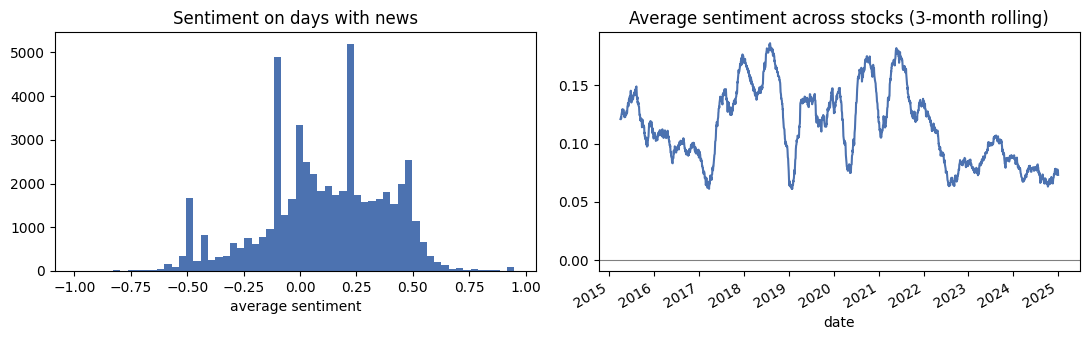

In [6]:
s = wide[SENT]
print(f"Range: {s.min().min():.3f} to {s.max().max():.3f}")
print(f"Share of stock-days with sentiment exactly 0: {(s == 0).mean().mean():.1%}")
nonzero = s.values[s.values != 0]
print(f"Among nonzero days: mean {nonzero.mean():+.3f}, median {np.median(nonzero):+.3f}, share positive {(nonzero > 0).mean():.1%}")

check("Sentiment within [-1, 1]", s.min().min() >= -1 and s.max().max() <= 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(nonzero, bins=60, color="#4c72b0"); ax[0].set_title("Sentiment on days with news"); ax[0].set_xlabel("average sentiment")
s.replace(0, np.nan).mean(axis=1).rolling(63).mean().plot(ax=ax[1], color="#4c72b0")
ax[1].axhline(0, color="gray", lw=0.8); ax[1].set_title("Average sentiment across stocks (3-month rolling)")
plt.tight_layout(); plt.show()

**What to look for:** news sentiment is usually **skewed positive** (companies issue lots of positive press releases). That is fine, but it means a sentiment of 0.1 is not "good news," just average. Standardizing each variable (using training statistics) handles this in the model.

## 4. News attention: is there a trend?

If the number of stories rises over the years, the model could mistake "more news overall" for a signal. Check the yearly average and test for a trend **in the training period**.

      avg attention  avg stories/day  days with news (%)
year                                                    
2015           1.83            15.68               81.39
2016           1.83            13.15               83.62
2017           1.81            12.76               81.57
2018           1.82            15.86               76.65
2019           1.86            15.42               77.06
2020           1.89            17.52               77.46
2021           1.97            16.12               84.62
2022           2.14            15.74               99.58
2023           2.08            14.97               99.73
2024           2.10            15.99               98.44


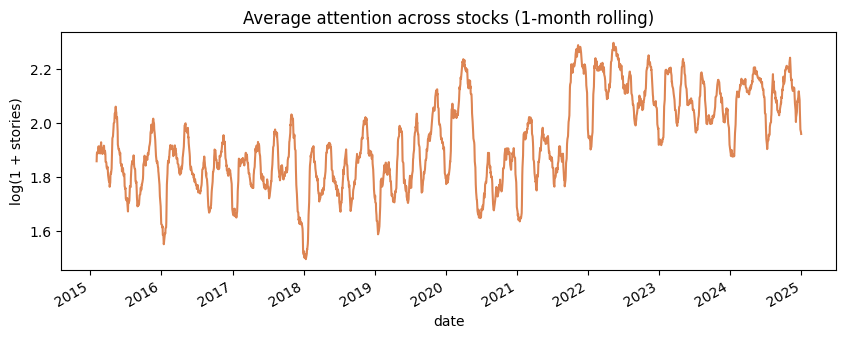

[OK] Attention stationary in training period (ADF p < 0.05): ADF p = 3.86e-09
[OK] Attention level stable 2015 -> 2021 (change < 20%): 1.83 -> 1.97


In [7]:
a = wide[ATTN]
yearly = pd.DataFrame({
    "avg attention": a.mean(axis=1).groupby(a.index.year).mean(),
    "avg stories/day": np.expm1(a).mean(axis=1).groupby(a.index.year).mean(),
    "days with news (%)": (a > 0).mean(axis=1).groupby(a.index.year).mean() * 100,
}).round(2)
yearly.index.name = "year"
print(yearly.to_string())

fig, ax = plt.subplots(figsize=(10, 3.5))
a.mean(axis=1).rolling(21).mean().plot(ax=ax, color="#dd8452")
ax.set_title("Average attention across stocks (1-month rolling)"); ax.set_ylabel("log(1 + stories)")
plt.show()

# Trend test on the training period: ADF test (small p-value = no persistent trend / stationary)
train_attn = train[ATTN].mean(axis=1)
p = adfuller(train_attn, regression="c")[1]
first, last = yearly["avg attention"].iloc[0], yearly.loc[2021, "avg attention"]
check("Attention stationary in training period (ADF p < 0.05)", p < 0.05, f"ADF p = {p:.3g}")
check("Attention level stable 2015 -> 2021 (change < 20%)", abs(last / first - 1) < 0.20, f"{first:.2f} -> {last:.2f}")

**If attention is FLAGGED:** a simple fix is to measure attention **relative to the stock's recent normal**, e.g., today's attention minus its average over the past 60 days ("abnormal attention"). That keeps the news spikes but removes slow trends in overall news volume.

## 5. Crisis check: March 2020

During the COVID crash, the market fell sharply, so news attention should spike and sentiment should drop. If the news data tracks real events, it should show up here.

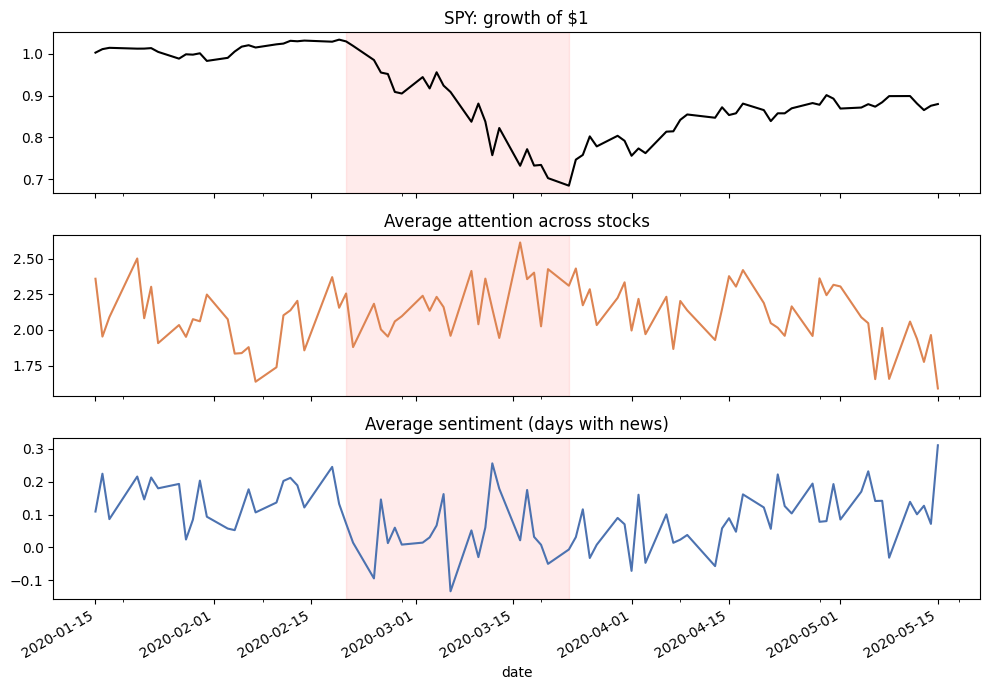

Attention: 2019 avg 1.86 vs crash 2.18
Sentiment: 2019 avg +0.127 vs crash +0.044
[OK] Attention higher during the crash
[OK] Sentiment lower during the crash


In [8]:
window = wide.loc["2020-01-15":"2020-05-15"]
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
(1 + window["SPY_ret"]).cumprod().plot(ax=ax[0], color="black"); ax[0].set_title("SPY: growth of $1")
window[ATTN].mean(axis=1).plot(ax=ax[1], color="#dd8452"); ax[1].set_title("Average attention across stocks")
window[SENT].replace(0, np.nan).mean(axis=1).plot(ax=ax[2], color="#4c72b0"); ax[2].set_title("Average sentiment (days with news)")
for axis in ax:
    axis.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-03-23"), color="red", alpha=0.08)
plt.tight_layout(); plt.show()

calm = wide.loc["2019-01-01":"2019-12-31"]
crash = wide.loc["2020-02-20":"2020-03-23"]
att_calm, att_crash = calm[ATTN].mean().mean(), crash[ATTN].mean().mean()
sent_calm = calm[SENT].replace(0, np.nan).mean().mean()
sent_crash = crash[SENT].replace(0, np.nan).mean().mean()
print(f"Attention: 2019 avg {att_calm:.2f} vs crash {att_crash:.2f}")
print(f"Sentiment: 2019 avg {sent_calm:+.3f} vs crash {sent_crash:+.3f}")
check("Attention higher during the crash", att_crash > att_calm)
check("Sentiment lower during the crash", sent_crash < sent_calm)

## 6. Correlations: do sectors move together?

Stocks in the same sector should be more correlated with each other than with other sectors. Computed on the **training period** only.

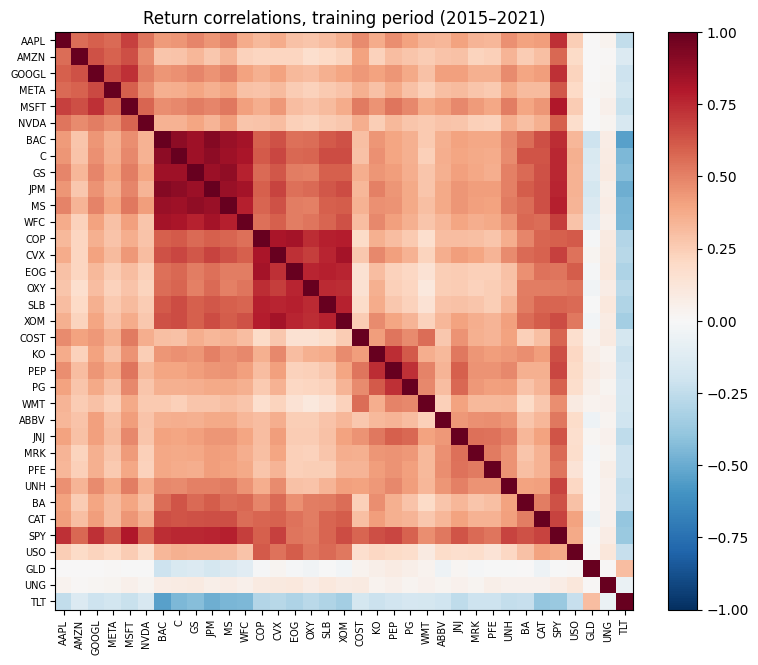

Average correlation within sectors:  0.66
Average correlation between sectors: 0.39
Oil (USO) vs energy stocks: 0.57   vs other stocks: 0.24
[OK] Within-sector correlation > between-sector
[OK] Oil correlates more with energy stocks than others


In [9]:
order = [t for sec in ["Tech", "Banks", "Energy", "Staples", "Healthcare", "Industrials"] for t in STOCKS if SECTOR.get(t) == sec]
order += ["SPY", "USO", "GLD", "UNG", "TLT"]
corr = train[[f"{t}_ret" for t in order]].corr()
corr.index = corr.columns = order

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=7); ax.set_yticks(range(len(order)), order, fontsize=7)
fig.colorbar(im, fraction=0.046); ax.set_title("Return correlations, training period (2015–2021)")
plt.show()

within, between = [], []
stock_order = [t for t in order if t in STOCKS]
for i, a1 in enumerate(stock_order):
    for b1 in stock_order[i + 1:]:
        (within if SECTOR[a1] == SECTOR[b1] else between).append(corr.loc[a1, b1])
print(f"Average correlation within sectors:  {np.mean(within):.2f}")
print(f"Average correlation between sectors: {np.mean(between):.2f}")
energy = [t for t in STOCKS if SECTOR.get(t) == "Energy"]
print(f"Oil (USO) vs energy stocks: {corr.loc['USO', energy].mean():.2f}   vs other stocks: {corr.loc['USO', [t for t in STOCKS if t not in energy]].mean():.2f}")
check("Within-sector correlation > between-sector", np.mean(within) > np.mean(between))
check("Oil correlates more with energy stocks than others", corr.loc["USO", energy].mean() > corr.loc["USO", [t for t in STOCKS if t not in energy]].mean())

## 7. News vs returns

- **Same day:** a stock's sentiment and its return should be positively related (good news, price up). This confirms the news is matched to the right company and day.
- **Next day:** sentiment today vs return tomorrow is the signal the GDBN could use. Expect it to be **small** (markets react fast).

Training period only; days with news only.

In [10]:
rows = []
for t in STOCKS:
    df = train[[f"{t}_sent", f"{t}_ret", f"{t}_attn"]].copy()
    df["next_ret"] = df[f"{t}_ret"].shift(-1)
    df = df[df[f"{t}_attn"] > 0].dropna()
    rows.append({"stock": t,
                 "same-day corr": df[f"{t}_sent"].corr(df[f"{t}_ret"]),
                 "next-day corr": df[f"{t}_sent"].corr(df["next_ret"])})
links = pd.DataFrame(rows).set_index("stock").sort_values("same-day corr")
print(links.round(3).to_string())
print(f"\nAverage same-day correlation: {links['same-day corr'].mean():+.3f}")
print(f"Average next-day correlation: {links['next-day corr'].mean():+.3f}")
check("Same-day sentiment-return link positive on average", links["same-day corr"].mean() > 0)
check("Same-day link stronger than next-day link", links["same-day corr"].mean() > links["next-day corr"].abs().mean())

       same-day corr  next-day corr
stock                              
MS             0.011         -0.014
BAC            0.014         -0.021
PFE            0.021          0.019
C              0.029         -0.010
WFC            0.031          0.023
JPM            0.031          0.006
PG             0.044          0.046
PEP            0.045         -0.011
SLB            0.050          0.028
ABBV           0.052         -0.005
KO             0.052          0.029
MRK            0.053          0.007
GS             0.062         -0.008
EOG            0.065         -0.014
CVX            0.070         -0.014
JNJ            0.070         -0.013
META           0.080         -0.009
MSFT           0.081          0.010
AMZN           0.082         -0.012
GOOGL          0.088          0.024
XOM            0.089         -0.046
UNH            0.091          0.015
WMT            0.094         -0.020
NVDA           0.100          0.007
OXY            0.102          0.027
COST           0.104        

**Reading this:** a clearly positive same-day correlation means the news data is aligned correctly. A tiny next-day correlation is normal: it is the hard part of prediction, and why the GDBN needs to be compared with simple baselines.

## 8. Summary

In [11]:
summary = pd.Series(flags).map({True: "OK", False: "FLAG"}).rename("result")
print(summary.to_string())
n_flag = int((~pd.Series(flags)).sum())
print(f"\n{len(flags) - n_flag} OK, {n_flag} FLAG")

95 variables                                              OK
No missing values                                         OK
No duplicate dates                                        OK
No gaps longer than 4 calendar days                       OK
No single-day move above ±60%                             OK
Average daily returns are small (|mean| < 0.5%)           OK
Sentiment within [-1, 1]                                  OK
Attention stationary in training period (ADF p < 0.05)    OK
Attention level stable 2015 -> 2021 (change < 20%)        OK
Attention higher during the crash                         OK
Sentiment lower during the crash                          OK
Within-sector correlation > between-sector                OK
Oil correlates more with energy stocks than others        OK
Same-day sentiment-return link positive on average        OK
Same-day link stronger than next-day link                 OK

15 OK, 0 FLAG
